# Book Spine OCR — Typography Grouping + Google Books Query Pipeline

## Objective

This version intentionally **does NOT classify TITLE / AUTHOR / OTHER**.

Instead it:

1. Detects text from each book spine.
2. Uses OCR polygons and perspective correction.
3. Re-recognizes difficult regions with targeted preprocessing.
4. Removes obvious OCR noise and duplicates.
5. Reconstructs fragmented text lines.
6. Measures **text size, text weight and visual style**.
7. Groups similar text by typography rather than semantic meaning.
8. Joins the typography groups into one comma-separated sentence.
9. Produces a `Google Books Query` suitable for the Google Books Volumes API.

### Example

```text
INTERNATIONAL, THINK & GROW RICH, NAPOLEON HILL
```

The purpose is to send the complete useful text from the spine to Google Books and let the metadata service determine the canonical book title and author.

### Important

- No Tesseract
- No DINOv2 / Transformers
- No KMeans semantic classifier
- No full-image 1x / 1.5x / 2x OCR
- Typography grouping is based on size / weight / visual style / geometry
- The final query preserves visual reading order


# PHASE 1 — Environment

## STEP 1 — Check versions and dependency conflicts

This cell intentionally avoids upgrading the environment.

It only installs **EasyOCR 1.7.2 if EasyOCR is missing** and then runs `pip check`.

The OCR pipeline does not require Tesseract, Transformers or DINOv2.


In [ ]:
# ============================================================
# PHASE 1 / STEP 1
# Environment check
# ============================================================

import sys
import subprocess
import importlib.util
from importlib import metadata

def package_version(name):
    try:
        return metadata.version(name)
    except Exception:
        return "not installed"

# Only install EasyOCR when it is actually missing.
if importlib.util.find_spec("easyocr") is None:
    print("EasyOCR not found. Installing EasyOCR 1.7.2...")
    subprocess.check_call([
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "easyocr==1.7.2"
    ])

print("Python       :", sys.version)
print("EasyOCR      :", package_version("easyocr"))
print("PyTorch      :", package_version("torch"))
print("TorchVision  :", package_version("torchvision"))
print("OpenCV       :", package_version("opencv-python-headless"))
print("NumPy        :", package_version("numpy"))
print("Pandas       :", package_version("pandas"))

print("\nRunning pip check...")
check = subprocess.run(
    [sys.executable, "-m", "pip", "check"],
    capture_output=True,
    text=True
)

if check.stdout.strip():
    print(check.stdout.strip())
else:
    print("No pip dependency conflicts reported.")

if check.stderr.strip():
    print(check.stderr.strip())


EasyOCR not found. Installing EasyOCR 1.7.2...
Python       : 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
EasyOCR      : 1.7.2
PyTorch      : 2.11.0+cu130
TorchVision  : 0.26.0+cu130
OpenCV       : 5.0.0.93
NumPy        : 2.1.3
Pandas       : 2.2.3
Pillow       : 11.3.0
scikit-learn : 1.6.1

Running pip check...
ipython 7.34.0 requires jedi, which is not installed.


## STEP 2 — Imports and GPU check

In [ ]:
# ============================================================
# PHASE 1 / STEP 2
# Imports
# ============================================================

import gc
import re
import math
from pathlib import Path
from difflib import SequenceMatcher

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tqdm.auto import tqdm

import torch
import easyocr

print("PyTorch :", torch.__version__)
print("CUDA    :", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU     :", torch.cuda.get_device_name(0))

gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()


PyTorch : 2.11.0+cu130
CUDA    : True
GPU     : Tesla T4


# PHASE 2 — Input

## STEP 3 — Configure input/output folders

The notebook expects **already extracted individual book spines**.

Example:

```text
/content/bookImg/
    book_01.jpg
    book_02.jpg
    book_03.jpg
    ...
```

For a real bookshelf application, your segmentation model should create these spine crops first.


In [ ]:
# ============================================================
# PHASE 2 / STEP 3
# Paths and configuration
# ============================================================

INPUT_DIR = Path("/content/bookImg")

OUTPUT_DIR = Path("/content/BookSpine_OCR_Final_Output")
ANNOTATED_DIR = OUTPUT_DIR / "annotated"
NORMALIZED_DIR = OUTPUT_DIR / "normalized_spines"

for d in [
    OUTPUT_DIR,
    ANNOTATED_DIR,
    NORMALIZED_DIR,
]:
    d.mkdir(parents=True, exist_ok=True)

extensions = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp",
    ".JPG", ".JPEG", ".PNG", ".BMP", ".WEBP"
}

image_files = sorted(
    p for p in INPUT_DIR.iterdir()
    if p.is_file() and p.suffix in extensions
)

if not image_files:
    raise FileNotFoundError(
        f"No images found in {INPUT_DIR}. "
        "Put individual book-spine images there."
    )

print(f"Found {len(image_files)} spine images.")
for p in image_files:
    print(" -", p.name)


Found 15 spine images.
 - book_01.jpg
 - book_02.jpg
 - book_03.jpg
 - book_04.jpg
 - book_05.jpg
 - book_06.jpg
 - book_07.jpg
 - book_08.jpg
 - book_09.jpg
 - book_10.jpg
 - book_11.jpg
 - book_12.jpg
 - book_13.jpg
 - book_14.jpg
 - book_15.jpg


# PHASE 3 — OCR Engine

## STEP 4 — Load EasyOCR

Only English is enabled because the supplied reference spines are English.

The recognizer uses beam search for better recognition quality.


In [ ]:

# ============================================================
# PHASE 3 / STEP 4
# EasyOCR
# ============================================================

USE_GPU = torch.cuda.is_available()

reader = easyocr.Reader(
    ["en"],
    gpu=USE_GPU,
    verbose=True
)

print("EasyOCR ready.")


Progress: |██████████████████████████████████████████████████| 100.0% Complete

Progress: |██████████████████████████████████████████████████| 100.0% CompleteEasyOCR ready.


# PHASE 4 — Spine Image Normalization

## STEP 5 — Normalize image resolution

Your supplied spine images are often very wide but only a few hundred pixels tall.

The OCR system therefore:

- keeps one normalized scale,
- upscales small spines,
- limits the maximum image size,
- avoids repeatedly running OCR at several full-image scales.

This replaces the old 1x / 1.5x / 2x full-image OCR strategy.


In [ ]:

# ============================================================
# PHASE 4 / STEP 5
# Image normalization
# ============================================================

MAX_LONG_SIDE = 4200
TARGET_HEIGHT = 480

def read_image(path):
    image = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)

    if image is None:
        raise ValueError(f"Could not read image: {path}")

    # Handle RGBA images.
    if image.ndim == 3 and image.shape[2] == 4:
        bgr = image[:, :, :3]
        alpha = image[:, :, 3:4].astype(np.float32) / 255.0
        white = np.full_like(bgr, 255)
        image = (
            bgr.astype(np.float32) * alpha
            + white.astype(np.float32) * (1 - alpha)
        ).astype(np.uint8)

    elif image.ndim == 2:
        image = cv2.cvtColor(image, cv2.COLOR_GRAY2BGR)

    return image

def normalize_spine(image):
    h, w = image.shape[:2]

    # Scale small images upward so thin letters have more pixels.
    scale_up = (
        TARGET_HEIGHT / h
        if h < TARGET_HEIGHT
        else 1.0
    )

    # Never exceed maximum long side.
    scale_down = (
        MAX_LONG_SIDE / max(h * scale_up, w * scale_up)
        if max(h * scale_up, w * scale_up) > MAX_LONG_SIDE
        else 1.0
    )

    scale = scale_up * scale_down

    if abs(scale - 1.0) < 0.01:
        return image.copy()

    interpolation = (
        cv2.INTER_CUBIC
        if scale > 1
        else cv2.INTER_AREA
    )

    return cv2.resize(
        image,
        None,
        fx=scale,
        fy=scale,
        interpolation=interpolation
    )

def save_normalized_spine(image, path):
    out = NORMALIZED_DIR / f"{Path(path).stem}_normalized.jpg"
    cv2.imwrite(str(out), image)
    return out


## STEP 6 — Optional safe deskew

Many spines have mild tilt.

This step estimates a dominant foreground angle and corrects only small rotations. Large or uncertain angles are left untouched to avoid damaging the image.


In [ ]:

# ============================================================
# PHASE 4 / STEP 6
# Safe deskew
# ============================================================

def estimate_foreground_angle(image):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # Detect strong edges.
    edges = cv2.Canny(gray, 50, 150)

    # Hough line estimate.
    lines = cv2.HoughLinesP(
        edges,
        1,
        np.pi / 180,
        threshold=max(30, image.shape[1] // 20),
        minLineLength=max(50, image.shape[1] // 10),
        maxLineGap=20
    )

    if lines is None:
        return 0.0

    angles = []

    for line in lines[:, 0]:
        x1, y1, x2, y2 = line

        dx = x2 - x1
        dy = y2 - y1

        if abs(dx) < 1:
            continue

        angle = math.degrees(math.atan2(dy, dx))

        # Only near-horizontal lines are useful here.
        if -15 <= angle <= 15:
            angles.append(angle)

    if not angles:
        return 0.0

    return float(np.median(angles))

def deskew_image(image, max_angle=10.0):
    angle = estimate_foreground_angle(image)

    if abs(angle) < 0.5 or abs(angle) > max_angle:
        return image.copy(), 0.0

    h, w = image.shape[:2]
    center = (w / 2, h / 2)

    matrix = cv2.getRotationMatrix2D(
        center,
        angle,
        1.0
    )

    rotated = cv2.warpAffine(
        image,
        matrix,
        (w, h),
        flags=cv2.INTER_CUBIC,
        borderMode=cv2.BORDER_CONSTANT,
        borderValue=(255, 255, 255)
    )

    return rotated, angle


# PHASE 5 — Text Detection

## STEP 7 — Run one high-quality text detection pass

The detector is tuned for:

- long horizontal book-spine text,
- thin characters,
- low-contrast printed text,
- slightly damaged covers.

A fallback detector pass is available only when the primary pass appears to have found too little text.


In [ ]:
# ============================================================
# PHASE 5 / STEP 7
# Text detection
# ============================================================

ALLOWED_CHARS = (
    "ABCDEFGHIJKLMNOPQRSTUVWXYZ"
    "abcdefghijklmnopqrstuvwxyz"
    "0123456789"
    ".,!?&'’:-/$*()"
)

DETECT_CONFIG = {
    "text_threshold": 0.40,
    "low_text": 0.20,
    "link_threshold": 0.20,
    "min_size": 6,
    "canvas_size": 3200,
    "mag_ratio": 1.0,
    "slope_ths": 0.15,
    "ycenter_ths": 0.35,
    "height_ths": 0.35,
    "width_ths": 0.50,
    "add_margin": 0.05,
    "contrast_ths": 0.05,
    "adjust_contrast": 0.50,
    "filter_ths": 0.003,
    "decoder": "beamsearch",
    "beamWidth": 5,
    "batch_size": 1,
    "paragraph": False,
    "allowlist": ALLOWED_CHARS,
}

FALLBACK_DETECT_CONFIG = {
    **DETECT_CONFIG,
    "text_threshold": 0.30,
    "low_text": 0.12,
    "link_threshold": 0.15,
    "height_ths": 0.28,
    "width_ths": 0.45,
}

def run_easyocr_detection(image, config):
    rgb = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )

    return reader.readtext(
        rgb,
        detail=1,
        **config
    )

def detections_to_regions(detections):
    regions = []

    for det in detections:
        if len(det) != 3:
            continue

        polygon, text, confidence = det

        text = clean_ocr_text(text)
        confidence = float(confidence)

        if not valid_ocr_text(text):
            continue

        polygon = np.asarray(
            polygon,
            dtype=np.float32
        )

        regions.append({
            "polygon": polygon.tolist(),
            "box": polygon_to_bbox(polygon),
            "text": text,
            "confidence": confidence
        })

    return regions


# PHASE 6 — Region Quality Filtering

## STEP 8 — Remove obvious OCR noise

The goal is **not** to discard small legitimate author text.

Instead, only remove high-confidence noise patterns such as:

- ISBN numbers,
- long numeric strings,
- barcode-like OCR,
- URLs,
- isolated one-character regions,
- extremely tiny low-confidence detections.

Publisher names and logos are not always removed here; they are usually classified as `OTHER`, preserving information for debugging.


In [ ]:
# ============================================================
# PHASE 6 / STEP 8
# Cleaning and duplicate removal
# ============================================================

MIN_REGION_HEIGHT_RATIO = 0.010
MIN_ALNUM_CHARACTERS = 2

ISBN_PATTERNS = [
    re.compile(r"^(?:ISBN[:\s-]*)?97[89][0-9Xx -]{9,}$"),
    re.compile(r"^[0-9Xx -]{10,}$"),
]

NOISE_WORDS = {
    "WWW",
    "HTTP",
    "HTTPS",
    "COM",
    "ORG",
    "NET",
}

def clean_ocr_text(text):
    if text is None:
        return ""

    text = str(text)
    text = text.replace("\n", " ")
    text = re.sub(r"\s+", " ", text)

    return text.strip(" |[]{}").strip()

def valid_ocr_text(text):
    text = clean_ocr_text(text)

    if len(text) < 2:
        return False

    alnum_count = sum(
        c.isalnum()
        for c in text
    )

    return alnum_count >= MIN_ALNUM_CHARACTERS

def polygon_to_bbox(polygon):
    pts = np.asarray(
        polygon,
        dtype=np.float32
    )

    return [
        float(pts[:, 0].min()),
        float(pts[:, 1].min()),
        float(pts[:, 0].max()),
        float(pts[:, 1].max())
    ]

def bbox_area(box):
    x1, y1, x2, y2 = box
    return max(0.0, x2-x1) * max(0.0, y2-y1)

def bbox_iou(a, b):
    ax1, ay1, ax2, ay2 = a
    bx1, by1, bx2, by2 = b

    ix1 = max(ax1, bx1)
    iy1 = max(ay1, by1)
    ix2 = min(ax2, bx2)
    iy2 = min(ay2, by2)

    inter = (
        max(0.0, ix2-ix1)
        * max(0.0, iy2-iy1)
    )

    union = (
        bbox_area(a)
        + bbox_area(b)
        - inter
    )

    return inter / union if union else 0.0

def bbox_area_ratio(a, b):
    aa = bbox_area(a)
    ab = bbox_area(b)

    if max(aa, ab) == 0:
        return 0.0

    return min(aa, ab) / max(aa, ab)

def normalized_for_comparison(text):
    text = clean_ocr_text(text).upper()
    text = re.sub(
        r"[^A-Z0-9 ]+",
        " ",
        text
    )
    return re.sub(
        r"\s+",
        " ",
        text
    ).strip()

def text_similarity(a, b):
    a = normalized_for_comparison(a)
    b = normalized_for_comparison(b)

    if not a or not b:
        return 0.0

    return SequenceMatcher(
        None,
        a,
        b
    ).ratio()

def looks_like_isbn(text):
    compact = re.sub(
        r"[\s-]+",
        "",
        text
    )

    return any(
        p.fullmatch(compact)
        for p in ISBN_PATTERNS
    )

def looks_like_url_or_noise(text):
    upper = text.upper()

    if any(
        token in upper
        for token in NOISE_WORDS
    ):
        return True

    if re.search(
        r"(https?://|www\.)",
        text,
        flags=re.IGNORECASE
    ):
        return True

    return False

def filter_regions(regions, image_shape):
    h_img = image_shape[0]

    filtered = []

    for region in regions:
        text = clean_ocr_text(region["text"])

        height = (
            region["box"][3]
            - region["box"][1]
        )

        height_ratio = (
            height / max(1, h_img)
        )

        # Very tiny boxes are usually logos/noise.
        # Keep somewhat larger small text because author lines
        # can legitimately be small.
        if (
            height_ratio < MIN_REGION_HEIGHT_RATIO
            and region["confidence"] < 0.70
        ):
            continue

        if looks_like_isbn(text):
            continue

        if looks_like_url_or_noise(text):
            continue

        region["height_ratio"] = float(height_ratio)
        filtered.append(region)

    return filtered

def deduplicate_regions(regions):
    # Highest confidence first.
    regions = sorted(
        regions,
        key=lambda r: (
            r["confidence"],
            r.get("height_ratio", 0.0)
        ),
        reverse=True
    )

    kept = []

    for candidate in regions:
        duplicate = False

        for existing in kept:

            iou = bbox_iou(
                candidate["box"],
                existing["box"]
            )

            area_ratio = bbox_area_ratio(
                candidate["box"],
                existing["box"]
            )

            text_sim = text_similarity(
                candidate["text"],
                existing["text"]
            )

            # Same region with high geometry overlap.
            if (
                iou >= 0.55
                and area_ratio >= 0.55
            ):
                duplicate = True
                break

            # Same text repeated in almost the same location.
            if (
                text_sim >= 0.90
                and iou >= 0.35
            ):
                duplicate = True
                break

        if not duplicate:
            kept.append(candidate)

    return kept


## STEP 9 — Adaptive detector fallback

We first trust the primary detector.

Only when it appears to have found very little useful text do we run **one fallback pass**.

This avoids the duplicate explosion from the old multi-scale pipeline.


In [ ]:

# ============================================================
# PHASE 6 / STEP 9
# Adaptive detection
# ============================================================

def adaptive_detect(image):
    primary_raw = run_easyocr_detection(
        image,
        DETECT_CONFIG
    )

    primary = detections_to_regions(
        primary_raw
    )

    primary = filter_regions(
        primary,
        image.shape
    )

    # Trigger fallback only when primary is clearly weak.
    primary_total_chars = sum(
        len(r["text"])
        for r in primary
    )

    should_fallback = (
        len(primary) == 0
        or (
            len(primary) <= 1
            and primary_total_chars < 8
        )
    )

    if not should_fallback:
        return deduplicate_regions(primary), "primary"

    fallback_raw = run_easyocr_detection(
        image,
        FALLBACK_DETECT_CONFIG
    )

    fallback = detections_to_regions(
        fallback_raw
    )

    fallback = filter_regions(
        fallback,
        image.shape
    )

    combined = deduplicate_regions(
        primary + fallback
    )

    return combined, "primary+fallback"


# PHASE 7 — Polygon Text Crops

## STEP 10 — Perspective-correct every OCR region

This is critical.

The OCR engine returns quadrilateral polygons. The polygon is transformed to a clean horizontal rectangle before recognition.

This prevents perspective distortion from weakening OCR.


In [ ]:
# ============================================================
# PHASE 7 / STEP 10
# Polygon perspective crop
# ============================================================

TEXT_CROP_MIN_HEIGHT = 48
TEXT_CROP_MAX_HEIGHT = 180

def order_quad_points(points):
    pts = np.asarray(
        points,
        dtype=np.float32
    )

    if pts.shape != (4, 2):
        return None

    s = pts.sum(axis=1)
    d = np.diff(
        pts,
        axis=1
    ).ravel()

    rect = np.zeros(
        (4, 2),
        dtype=np.float32
    )

    rect[0] = pts[np.argmin(s)]  # TL
    rect[2] = pts[np.argmax(s)]  # BR
    rect[1] = pts[np.argmin(d)]  # TR
    rect[3] = pts[np.argmax(d)]  # BL

    return rect

def perspective_text_crop(
    image,
    polygon,
    padding=8
):
    pts = np.asarray(
        polygon,
        dtype=np.float32
    )

    if pts.shape != (4, 2):
        x1,y1,x2,y2 = polygon_to_bbox(pts)

        x1 = max(
            0,
            int(round(x1)) - padding
        )
        y1 = max(
            0,
            int(round(y1)) - padding
        )
        x2 = min(
            image.shape[1],
            int(round(x2)) + padding
        )
        y2 = min(
            image.shape[0],
            int(round(y2)) + padding
        )

        return (
            image[y1:y2, x1:x2].copy()
            if x2 > x1 and y2 > y1
            else None
        )

    rect = order_quad_points(pts)

    if rect is None:
        return None

    tl, tr, br, bl = rect

    def dist(a, b):
        return float(
            np.linalg.norm(a-b)
        )

    width = max(
        dist(tl, tr),
        dist(bl, br)
    )

    height = max(
        dist(tl, bl),
        dist(tr, br)
    )

    width = int(round(width))
    height = int(round(height))

    if width < 3 or height < 3:
        return None

    dst_w = width + 2 * padding
    dst_h = height + 2 * padding

    dst = np.array([
        [padding, padding],
        [dst_w-padding-1, padding],
        [dst_w-padding-1, dst_h-padding-1],
        [padding, dst_h-padding-1]
    ], dtype=np.float32)

    matrix = cv2.getPerspectiveTransform(
        rect,
        dst
    )

    crop = cv2.warpPerspective(
        image,
        matrix,
        (dst_w, dst_h),
        flags=cv2.INTER_CUBIC,
        borderMode=cv2.BORDER_CONSTANT,
        borderValue=(255,255,255)
    )

    return crop if crop.size else None

def resize_text_crop_for_recognition(crop):
    h = crop.shape[0]

    if h < TEXT_CROP_MIN_HEIGHT:
        scale = TEXT_CROP_MIN_HEIGHT / max(1, h)

    elif h > TEXT_CROP_MAX_HEIGHT:
        scale = TEXT_CROP_MAX_HEIGHT / h

    else:
        scale = 1.0

    if abs(scale-1.0) < 0.01:
        return crop

    return cv2.resize(
        crop,
        None,
        fx=scale,
        fy=scale,
        interpolation=(
            cv2.INTER_CUBIC
            if scale > 1
            else cv2.INTER_AREA
        )
    )


# PHASE 8 — Recognition Improvement

## STEP 11 — Selective preprocessing

Preprocessing is applied **only to individual difficult text crops**.

Variants:

- Original
- CLAHE-enhanced grayscale
- Otsu threshold

We do not run these expensive variants over the entire spine.


In [ ]:

# ============================================================
# PHASE 8 / STEP 11
# Recognition variants
# ============================================================

RECOGNITION_CONFIDENCE_THRESHOLD = 0.72

def recognition_variants(crop):
    variants = [
        ("original", crop)
    ]

    gray = cv2.cvtColor(
        crop,
        cv2.COLOR_BGR2GRAY
    )

    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8,8)
    )

    enhanced = clahe.apply(gray)

    variants.append((
        "clahe",
        cv2.cvtColor(
            enhanced,
            cv2.COLOR_GRAY2BGR
        )
    ))

    _, otsu = cv2.threshold(
        enhanced,
        0,
        255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    variants.append((
        "otsu",
        cv2.cvtColor(
            otsu,
            cv2.COLOR_GRAY2BGR
        )
    ))

    return variants

def recognize_text_crop(crop):
    results = []

    for variant_name, variant in recognition_variants(crop):

        rgb = cv2.cvtColor(
            variant,
            cv2.COLOR_BGR2RGB
        )

        try:
            detections = reader.readtext(
                rgb,
                detail=1,
                paragraph=False,

                decoder="beamsearch",
                beamWidth=5,

                allowlist=ALLOWED_CHARS,

                contrast_ths=0.05,
                adjust_contrast=0.50,
                filter_ths=0.003,

                text_threshold=0.35,
                low_text=0.15,
                link_threshold=0.15,

                canvas_size=2600,
                mag_ratio=1.15,

                batch_size=1
            )
        except Exception:
            continue

        if not detections:
            continue

        best = max(
            detections,
            key=lambda x: float(x[2])
        )

        text = clean_ocr_text(best[1])
        confidence = float(best[2])

        if valid_ocr_text(text):
            results.append({
                "variant": variant_name,
                "text": text,
                "confidence": confidence
            })

    if not results:
        return {
            "text": "",
            "confidence": 0.0,
            "variant": None,
            "agreement": 0
        }

    best = None
    best_score = -1.0
    best_agreement = 0

    for candidate in results:

        agreement = sum(
            text_similarity(
                candidate["text"],
                other["text"]
            ) >= 0.72
            for other in results
            if other is not candidate
        )

        # Confidence plus agreement.
        score = (
            candidate["confidence"]
            + 0.08 * agreement
        )

        if score > best_score:
            best_score = score
            best = candidate
            best_agreement = agreement

    return {
        "text": best["text"],
        "confidence": float(best["confidence"]),
        "variant": best["variant"],
        "agreement": int(best_agreement)
    }


## STEP 12 — Improve recognition of low-confidence regions

High-confidence EasyOCR detections are kept.

Only low-confidence regions are re-recognized on the polygon crop.


In [ ]:
# ============================================================
# PHASE 8 / STEP 12
# Region recognition
# ============================================================

def refine_region_recognition(
    image,
    region
):
    # Keep strong detections without unnecessary cropping.
    if region["confidence"] >= RECOGNITION_CONFIDENCE_THRESHOLD:
        return region

    crop = perspective_text_crop(
        image,
        region["polygon"],
        padding=8
    )

    if crop is None:
        return region

    crop = resize_text_crop_for_recognition(
        crop
    )

    retry = recognize_text_crop(
        crop
    )

    if (
        retry["text"]
        and retry["confidence"]
        >= region["confidence"]
    ):
        region["text"] = retry["text"]
        region["confidence"] = retry["confidence"]

    return region


# PHASE 9 — Text Line Reconstruction

## STEP 13 — Merge text fragments into complete visual lines

OCR sometimes returns:

```text
THE SUBTLE ART OF NOT
GIVING A F*CK
```

as two regions.

This stage merges fragments that are on the same visual line using:

- vertical overlap,
- similar text height,
- horizontal gap.

This is separate from duplicate removal.


In [ ]:

# ============================================================
# PHASE 9 / STEP 13
# Text-line grouping
# ============================================================

LINE_VERTICAL_OVERLAP = 0.45
LINE_HEIGHT_RATIO_MIN = 0.55
LINE_HEIGHT_RATIO_MAX = 1.80
LINE_GAP_FACTOR = 2.5

def vertical_overlap(a, b):
    inter = max(
        0.0,
        min(a[3], b[3]) - max(a[1], b[1])
    )

    denom = min(
        max(1.0, a[3]-a[1]),
        max(1.0, b[3]-b[1])
    )

    return inter / denom

def horizontal_gap(a, b):
    if a[0] <= b[0]:
        return max(0.0, b[0]-a[2])

    return max(0.0, a[0]-b[2])

def should_group_same_line(a, b):
    h1 = max(
        1.0,
        a["box"][3]-a["box"][1]
    )

    h2 = max(
        1.0,
        b["box"][3]-b["box"][1]
    )

    ratio = h1 / h2

    if not (
        LINE_HEIGHT_RATIO_MIN
        <= ratio
        <= LINE_HEIGHT_RATIO_MAX
    ):
        return False

    if vertical_overlap(
        a["box"],
        b["box"]
    ) < LINE_VERTICAL_OVERLAP:
        return False

    gap = horizontal_gap(
        a["box"],
        b["box"]
    )

    return (
        gap
        <= LINE_GAP_FACTOR * min(h1,h2)
    )

def group_text_lines(regions):
    if not regions:
        return []

    regions = sorted(
        regions,
        key=lambda r: (
            (r["box"][1]+r["box"][3])/2,
            r["box"][0]
        )
    )

    groups = []

    for region in regions:
        assigned = False

        for group in groups:

            reference = group[-1]

            if should_group_same_line(
                reference,
                region
            ):
                group.append(region)
                assigned = True
                break

        if not assigned:
            groups.append([region])

    lines = []

    for line_id, group in enumerate(groups):

        group = sorted(
            group,
            key=lambda r: r["box"][0]
        )

        text = " ".join(
            clean_ocr_text(r["text"])
            for r in group
        )

        x1 = min(
            r["box"][0]
            for r in group
        )

        y1 = min(
            r["box"][1]
            for r in group
        )

        x2 = max(
            r["box"][2]
            for r in group
        )

        y2 = max(
            r["box"][3]
            for r in group
        )

        confidence = float(
            np.mean([
                r["confidence"]
                for r in group
            ])
        )

        lines.append({
            "line_id": line_id,
            "members": group,
            "text": clean_ocr_text(text),
            "confidence": confidence,
            "box": [x1,y1,x2,y2]
        })

    return lines


# PHASE 10 — Typography Analysis

## STEP 14 — Classify text size

The size is **relative to the current book spine**, not absolute pixels.

Outputs:

- LARGE
- MEDIUM
- SMALL

This makes the system less sensitive to different camera resolutions.


In [ ]:
# ============================================================
# PHASE 10 / STEP 14
# Typography features: size + stroke width + visual style
# ============================================================

def estimate_stroke_width(image, box):
    """Estimate relative text stroke width from a cropped OCR line."""
    x1, y1, x2, y2 = map(int, [round(v) for v in box])
    pad = 4

    x1 = max(0, x1 - pad)
    y1 = max(0, y1 - pad)
    x2 = min(image.shape[1], x2 + pad)
    y2 = min(image.shape[0], y2 + pad)

    crop = image[y1:y2, x1:x2]

    if crop.size == 0:
        return 0.0, 0.0

    gray = cv2.cvtColor(crop, cv2.COLOR_BGR2GRAY)
    gray = cv2.GaussianBlur(gray, (3, 3), 0)

    _, binary = cv2.threshold(
        gray, 0, 255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    candidates = [binary, 255 - binary]
    plausible = []

    for mask in candidates:
        ratio = float(np.mean(mask > 0))
        if 0.01 <= ratio <= 0.45:
            plausible.append((abs(ratio - 0.18), mask))

    if plausible:
        selected = min(plausible, key=lambda x: x[0])[1]
    else:
        selected = min(
            candidates,
            key=lambda m: float(np.mean(m > 0))
        )

    fg = (selected > 0).astype(np.uint8) * 255

    kernel = np.ones((2, 2), np.uint8)
    fg = cv2.morphologyEx(
        fg,
        cv2.MORPH_OPEN,
        kernel
    )

    if not np.any(fg > 0):
        return 0.0, 0.0

    dist = cv2.distanceTransform(
        fg,
        cv2.DIST_L2,
        3
    )

    values = dist[fg > 0]

    if values.size == 0:
        return 0.0, 0.0

    stroke_px = float(
        np.percentile(values, 75) * 2.0
    )

    normalized = stroke_px / max(1, crop.shape[0])

    return stroke_px, normalized


def detect_case_style(text):
    text = clean_ocr_text(text)
    letters = [c for c in text if c.isalpha()]

    if not letters:
        return "NUMERIC_OR_SYMBOL"

    upper = sum(c.isupper() for c in letters) / len(letters)
    lower = sum(c.islower() for c in letters) / len(letters)

    words = [w for w in text.split() if w]

    title_case_words = sum(
        bool(re.match(r"^[A-Z][a-z]", w))
        for w in words
    )

    if upper >= 0.85:
        return "ALL_CAPS"
    if lower >= 0.85:
        return "LOWER_CASE"
    if words and title_case_words / len(words) >= 0.60:
        return "TITLE_CASE"

    return "MIXED_CASE"


def typography_features(line, image_shape, image):
    h_img, w_img = image_shape[:2]
    x1, y1, x2, y2 = line["box"]

    width = max(1.0, x2 - x1)
    height = max(1.0, y2 - y1)
    text = clean_ocr_text(line["text"])

    stroke_px, stroke_norm = estimate_stroke_width(
        image,
        line["box"]
    )

    return {
        "line_id": line["line_id"],
        "text": text,
        "confidence": float(line["confidence"]),
        "x1": float(x1),
        "normalized_height": height / max(1.0, h_img),
        "normalized_width": width / max(1.0, w_img),
        "aspect_ratio": width / height,
        "center_x": ((x1 + x2) / 2) / max(1.0, w_img),
        "center_y": ((y1 + y2) / 2) / max(1.0, h_img),
        "stroke_width_px": stroke_px,
        "normalized_stroke_width": stroke_norm,
        "visual_style": detect_case_style(text),
        "line": line,
    }


def assign_size_classes(rows):
    if not rows:
        return rows

    heights = np.array([
        r["normalized_height"]
        for r in rows
    ], dtype=float)

    if len(rows) == 1:
        classes = ["LARGE"]
    elif len(rows) == 2:
        order = np.argsort(heights)
        classes = [None] * len(rows)
        classes[order[0]] = "SMALL"
        classes[order[1]] = "LARGE"
    else:
        q33, q66 = np.quantile(
            heights,
            [0.33, 0.66]
        )
        classes = [
            "SMALL" if h <= q33
            else "MEDIUM" if h <= q66
            else "LARGE"
            for h in heights
        ]

    for row, cls in zip(rows, classes):
        row["size_class"] = cls

    return rows


## STEP 15 — Estimate text weight and style

Each OCR line now gets:

- **Size:** LARGE / MEDIUM / SMALL
- **Weight:** LIGHT / MEDIUM / BOLD
- **Style:** ALL_CAPS / TITLE_CASE / LOWER_CASE / MIXED_CASE / NUMERIC_OR_SYMBOL

These describe typography only. They do not mean TITLE or AUTHOR.


In [ ]:
# ============================================================
# PHASE 10 / STEP 15
# Typography weight classification
# ============================================================

def assign_weight_classes(rows):
    if not rows:
        return rows

    widths = np.array([
        r.get("normalized_stroke_width", 0.0)
        for r in rows
    ], dtype=float)

    valid = widths[widths > 0]

    if valid.size == 0:
        classes = ["MEDIUM"] * len(rows)
    elif len(rows) == 1:
        classes = ["MEDIUM"]
    elif len(rows) == 2:
        order = np.argsort(widths)
        classes = [None] * len(rows)
        classes[order[0]] = "LIGHT"
        classes[order[1]] = "BOLD"
    else:
        q33, q66 = np.quantile(valid,[0.33,0.66])
        classes = [
            "LIGHT" if w <= q33
            else "MEDIUM" if w <= q66
            else "BOLD"
            for w in widths
        ]

    for row, cls in zip(rows, classes):
        row["weight_class"] = cls

    return rows


# PHASE 11 — Typography Grouping

## STEP 16 — Group OCR text by typography

There is intentionally **no TITLE / AUTHOR / OTHER classification**.

Each reconstructed OCR line is grouped using:

- text size
- text weight
- visual style
- normalized stroke width
- normalized text height
- aspect ratio

The original visual reading order is preserved for the final Google Books query.


In [ ]:
# ============================================================
# PHASE 11 / STEP 16
# Typography grouping
# ============================================================

def typography_distance(a, b):
    eps = 1e-6

    height_distance = abs(math.log(
        (a["normalized_height"] + eps) /
        (b["normalized_height"] + eps)
    ))

    stroke_distance = abs(math.log(
        (a["normalized_stroke_width"] + eps) /
        (b["normalized_stroke_width"] + eps)
    ))

    aspect_distance = abs(math.log(
        (a["aspect_ratio"] + eps) /
        (b["aspect_ratio"] + eps)
    ))

    style_penalty = (
        0.0
        if a["visual_style"] == b["visual_style"]
        else 0.45
    )

    size_penalty = (
        0.0
        if a.get("size_class") == b.get("size_class")
        else 0.25
    )

    weight_penalty = (
        0.0
        if a.get("weight_class") == b.get("weight_class")
        else 0.25
    )

    return (
        0.75 * height_distance
        + 0.65 * stroke_distance
        + 0.20 * aspect_distance
        + style_penalty
        + size_penalty
        + weight_penalty
    )


def group_by_typography(rows):
    if not rows:
        return []

    ordered = sorted(
        rows,
        key=lambda r: (r["center_y"], r["x1"])
    )

    # Tune this value later on your own labeled examples.
    TYPOGRAPHY_DISTANCE_THRESHOLD = 1.55

    groups = []

    for row in ordered:
        best_group = None
        best_distance = float("inf")

        for group in groups:
            distance = min(
                typography_distance(row, member)
                for member in group["members"]
            )

            if distance < best_distance:
                best_distance = distance
                best_group = group

        if (
            best_group is not None
            and best_distance <= TYPOGRAPHY_DISTANCE_THRESHOLD
        ):
            best_group["members"].append(row)
        else:
            groups.append({"members": [row]})

    output = []

    for group in groups:
        members = sorted(
            group["members"],
            key=lambda r: (r["center_y"], r["x1"])
        )

        group_text = clean_ocr_text(
            " ".join(
                r["text"]
                for r in members
                if valid_ocr_text(r["text"])
            )
        )

        if not group_text:
            continue

        size_counts = {}
        weight_counts = {}
        style_counts = {}

        for r in members:
            size_counts[r["size_class"]] = size_counts.get(r["size_class"], 0) + 1
            weight_counts[r["weight_class"]] = weight_counts.get(r["weight_class"], 0) + 1
            style_counts[r["visual_style"]] = style_counts.get(r["visual_style"], 0) + 1

        output.append({
            "text": group_text,
            "members": members,
            "size_class": max(size_counts, key=size_counts.get),
            "weight_class": max(weight_counts, key=weight_counts.get),
            "visual_style": max(style_counts, key=style_counts.get),
            "median_height": float(np.median([
                r["normalized_height"] for r in members
            ])),
            "median_stroke_width": float(np.median([
                r["normalized_stroke_width"] for r in members
            ])),
            "center_y": float(np.mean([
                r["center_y"] for r in members
            ])),
            "x1": min(r["x1"] for r in members),
        })

    output.sort(
        key=lambda g: (g["center_y"], g["x1"])
    )

    for new_id, group in enumerate(output):
        group["group_id"] = new_id
        for member in group["members"]:
            member["typography_group"] = new_id

    return output


# PHASE 12 — Google Books Query

## STEP 17 — Join groups with commas

The final field is a single query string. Example:

```text
INTERNATIONAL, THINK & GROW RICH, NAPOLEON HILL
```

This query contains the useful visible spine text without trying to decide which part is the title and which part is the author.


In [ ]:
# ============================================================
# PHASE 12 / STEP 17
# Google Books query construction
# ============================================================

def clean_query_text(text):
    text = clean_ocr_text(text)
    text = re.sub(r"\s*,\s*", ", ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip(" ,")


def build_google_books_query(groups):
    parts = []

    for group in sorted(
        groups,
        key=lambda g: (g["center_y"], g["x1"])
    ):
        text = clean_query_text(group["text"])
        if text:
            parts.append(text)

    return ", ".join(parts)


# PHASE 13 — Full Pipeline

## STEP 18 — Process every spine

```text
spine image
  ↓
normalization + safe deskew
  ↓
one-pass OCR detection
  ↓
noise filtering + duplicate removal
  ↓
polygon perspective crop
  ↓
selective recognition retry
  ↓
text-line reconstruction
  ↓
size + weight + style analysis
  ↓
typography grouping
  ↓
comma-separated Google Books query
```


In [ ]:
# ============================================================
# PHASE 13 / STEP 18
# Main processing
# ============================================================

results = []

for image_path in tqdm(
    image_files,
    desc="Processing book spines"
):
    try:
        image = read_image(image_path)
        image = normalize_spine(image)
        image, deskew_angle = deskew_image(image)

        save_normalized_spine(
            image,
            image_path
        )

        regions, detector_mode = adaptive_detect(
            image
        )

        refined = [
            refine_region_recognition(image, region)
            for region in regions
        ]

        refined = deduplicate_regions(refined)

        lines = group_text_lines(refined)

        rows = [
            typography_features(
                line,
                image.shape,
                image
            )
            for line in lines
        ]

        rows = assign_size_classes(rows)
        rows = assign_weight_classes(rows)
        groups = group_by_typography(rows)

        query = build_google_books_query(groups)

        all_text = " | ".join(
            r["text"]
            for r in rows
            if valid_ocr_text(r["text"])
        )

        results.append({
            "file": image_path.name,
            "google_books_query": query,
            "all_text": all_text,
            "ocr_confidence": float(
                np.mean([
                    r["confidence"]
                    for r in rows
                ]) if rows else 0.0
            ),
            "num_text_lines": len(rows),
            "num_typography_groups": len(groups),
            "grouping_method": detector_mode,
            "deskew_angle": float(deskew_angle),
            "groups": groups,
            "regions": rows,
            "image": image,
        })

    except Exception as e:
        print(
            f"FAILED: {image_path.name}: "
            f"{type(e).__name__}: {e}"
        )

        results.append({
            "file": image_path.name,
            "google_books_query": "",
            "all_text": "",
            "ocr_confidence": 0.0,
            "num_text_lines": 0,
            "num_typography_groups": 0,
            "grouping_method": "failed",
            "deskew_angle": 0.0,
            "groups": [],
            "regions": [],
            "image": None,
        })

print(
    f"\nCompleted {len(results)} spines."
)


Processing book spines:   0%|          | 0/15 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/easyocr/utils.py:249: RuntimeWarning: overflow encountered in scalar add
  curr.entries[newLabeling].prTotal += prNonBlank
/usr/local/lib/python3.13/dist-packages/easyocr/utils.py:248: RuntimeWarning: overflow encountered in scalar add
  curr.entries[newLabeling].prNonBlank += prNonBlank
/usr/local/lib/python3.13/dist-packages/easyocr/utils.py:221: RuntimeWarning: overflow encountered in scalar add
  curr.entries[labeling].prTotal += prBlank + prNonBlank
/usr/local/lib/python3.13/dist-packages/easyocr/utils.py:219: RuntimeWarning: overflow encountered in scalar add
  curr.entries[labeling].prNonBlank += prNonBlank



Completed 15 spines.


# PHASE 14 — Results

## STEP 19 — API-ready table

The main output is `Google Books Query`.

Example:

```text
INTERNATIONAL, THINK & GROW RICH, NAPOLEON HILL
```


In [ ]:
# ============================================================
# PHASE 14 / STEP 19
# Final API-ready table
# ============================================================

summary_rows = []

for result in results:
    summary_rows.append({
        "Book": result["file"],
        "Google Books Query": result["google_books_query"],
        "All OCR": result["all_text"],
        "OCR Confidence": round(result["ocr_confidence"],3),
        "Text Lines": result["num_text_lines"],
        "Typography Groups": result["num_typography_groups"],
        "Detector": result["grouping_method"],
        "Deskew Angle": round(result["deskew_angle"],2),
    })

final_df = pd.DataFrame(summary_rows)
display(final_df)

final_df.to_csv(
    OUTPUT_DIR / "book_spine_google_books_queries.csv",
    index=False
)


,Book,Google Books Query,All OCR,OCR Confidence,Text Lines,Typography Groups,Detector,Deskew Angle
0,book_01.jpg,ITENDSWITHUS COLLEENHOOVER,ITENDSWITHUS COLLEENHOOVER,0.879,1,1,primary,0.00
1,book_02.jpg,"BEFIAnCIALLYSMART Iink, NITA MENEZES",NITA | BEFIAnCIALLYSMART Iink | MENEZES,0.847,3,2,primary,-0.87
2,book_03.jpg,Dafindoutl Animals,Dafindoutl | Animals,0.732,2,1,primary,0.00
3,book_04.jpg,Dafindoutl Science,Dafindoutl | Science,0.758,2,1,primary,0.00
4,book_05.jpg,JASONFRIED& REWORK DAVIDHEINEMEIRHAN,JASONFRIED& | REWORK | DAVIDHEINEMEIRHAN,0.993,3,1,primary,0.00
5,book_06.jpg,HOWTOWINFRIENDS DALECARNECIE &INFLUENCEPEOPLE,HOWTOWINFRIENDS | DALECARNECIE | &INFLUENCEPEOPLE,0.878,3,1,primary,0.00
6,book_07.jpg,DEEPWORKCalNewport,DEEPWORKCalNewport,0.782,1,1,primary,0.00
7,book_08.jpg,"MUTUDEISEVERYTHING JEFF-KELLER, Jib",MUTUDEISEVERYTHING | JEFF-KELLER | Jib,0.334,3,2,primary,0.00
8,book_09.jpg,INTERNATIONAL THINK&GROWRICH BXNAPOLEONHILL BE...,INTERNATIONAL | THINK&GROWRICH BXNAPOLEONHILL ...,0.618,4,2,primary,0.00
9,book_10.jpg,inldistractlable NirEyal,inldistractlable NirEyal,0.920,1,1,primary,0.00


## STEP 20 — Typography group diagnostics

In [ ]:
# ============================================================
# PHASE 14 / STEP 20
# Typography groups
# ============================================================

group_rows = []

for result in results:
    for group in result["groups"]:
        group_rows.append({
            "Book": result["file"],
            "Group ID": group["group_id"],
            "Group Text": group["text"],
            "Size": group["size_class"],
            "Weight": group["weight_class"],
            "Visual Style": group["visual_style"],
            "Median Height": round(group["median_height"],5),
            "Median Stroke Width": round(group["median_stroke_width"],5),
        })

groups_df = pd.DataFrame(group_rows)
display(groups_df)

groups_df.to_csv(
    OUTPUT_DIR / "typography_groups.csv",
    index=False
)


,Book,Group ID,Group Text,Size,Weight,Visual Style,Median Height,Median Stroke Width
0,book_01.jpg,0,ITENDSWITHUS COLLEENHOOVER,LARGE,MEDIUM,ALL_CAPS,0.52708,0.07318
1,book_02.jpg,0,BEFIAnCIALLYSMART Iink,LARGE,MEDIUM,MIXED_CASE,0.30826,0.06511
2,book_02.jpg,1,NITA MENEZES,MEDIUM,BOLD,ALL_CAPS,0.12294,0.07441
3,book_03.jpg,0,Dafindoutl Animals,SMALL,LIGHT,LOWER_CASE,0.30937,0.08523
4,book_04.jpg,0,Dafindoutl Science,SMALL,LIGHT,LOWER_CASE,0.36354,0.08258
5,book_05.jpg,0,JASONFRIED& REWORK DAVIDHEINEMEIRHAN,MEDIUM,LIGHT,ALL_CAPS,0.16042,0.06599
6,book_06.jpg,0,HOWTOWINFRIENDS DALECARNECIE &INFLUENCEPEOPLE,MEDIUM,MEDIUM,ALL_CAPS,0.20208,0.10914
7,book_07.jpg,0,DEEPWORKCalNewport,LARGE,MEDIUM,MIXED_CASE,0.56042,0.14779
8,book_08.jpg,0,MUTUDEISEVERYTHING JEFF-KELLER,MEDIUM,MEDIUM,ALL_CAPS,0.45312,0.07250
9,book_08.jpg,1,Jib,SMALL,BOLD,TITLE_CASE,0.41458,0.14641


## STEP 21 — Detailed OCR region diagnostics

In [ ]:
# ============================================================
# PHASE 14 / STEP 21
# OCR region diagnostics
# ============================================================

region_rows = []

for result in results:
    for r in result["regions"]:
        region_rows.append({
            "Book": result["file"],
            "Line ID": r["line_id"],
            "Typography Group": r.get("typography_group", -1),
            "Text": r["text"],
            "Size": r["size_class"],
            "Weight": r["weight_class"],
            "Visual Style": r["visual_style"],
            "OCR Confidence": round(r["confidence"],3),
            "Normalized Height": round(r["normalized_height"],5),
            "Normalized Stroke Width": round(r["normalized_stroke_width"],5),
            "Stroke Width PX": round(r["stroke_width_px"],2),
            "Normalized Width": round(r["normalized_width"],5),
            "Aspect Ratio": round(r["aspect_ratio"],3),
            "Center X": round(r["center_x"],3),
            "Center Y": round(r["center_y"],3),
        })

regions_df = pd.DataFrame(region_rows)
display(regions_df)

regions_df.to_csv(
    OUTPUT_DIR / "text_region_diagnostics.csv",
    index=False
)


,Book,Line ID,Typography Group,Text,Size,Weight,Visual Style,OCR Confidence,Normalized Height,Normalized Stroke Width,Stroke Width PX,Normalized Width,Aspect Ratio,Center X,Center Y,Recognition Variant,Recognition Agreement
0,book_01.jpg,0,0,ITENDSWITHUS COLLEENHOOVER,LARGE,MEDIUM,ALL_CAPS,0.879,0.52708,0.07318,19.10,0.79287,10.727,0.460,0.516,,0
1,book_02.jpg,0,1,NITA,MEDIUM,BOLD,ALL_CAPS,0.996,0.12477,0.09720,7.39,0.07407,2.059,0.213,0.725,,0
2,book_02.jpg,1,0,BEFIAnCIALLYSMART Iink,LARGE,MEDIUM,MIXED_CASE,0.546,0.30826,0.06511,11.46,0.63439,7.137,0.611,0.772,,0
3,book_02.jpg,2,1,MENEZES,SMALL,LIGHT,ALL_CAPS,0.999,0.12110,0.05162,3.82,0.14286,4.091,0.220,0.826,,0
4,book_03.jpg,0,0,Dafindoutl,SMALL,LIGHT,LOWER_CASE,0.465,0.26875,0.08365,11.46,0.10281,3.287,0.194,0.574,,0
5,book_03.jpg,1,0,Animals,LARGE,BOLD,LOWER_CASE,0.999,0.35000,0.08682,15.28,0.11081,2.720,0.444,0.590,,0
6,book_04.jpg,0,0,Dafindoutl,SMALL,LIGHT,LOWER_CASE,0.584,0.33333,0.06821,11.46,0.10389,2.606,0.195,0.544,,0
7,book_04.jpg,1,0,Science,LARGE,BOLD,LOWER_CASE,0.932,0.39375,0.09695,19.10,0.09243,1.963,0.451,0.551,,0
8,book_05.jpg,0,0,JASONFRIED&,MEDIUM,LIGHT,ALL_CAPS,1.000,0.16042,0.06444,5.48,0.20766,5.636,0.634,0.632,,0
9,book_05.jpg,1,0,REWORK,LARGE,MEDIUM,ALL_CAPS,0.999,0.32917,0.06599,10.95,0.27225,3.601,0.214,0.679,,0


# PHASE 15 — Visualization

## STEP 22 — Annotated typography groups

Each polygon is labeled with:

`GROUP | SIZE | WEIGHT | STYLE | OCR TEXT`

There are no semantic TITLE/AUTHOR labels.


In [ ]:
# ============================================================
# PHASE 15 / STEP 22
# Visualization
# ============================================================

SIZE_COLORS = {
    "LARGE": (0,180,0),
    "MEDIUM": (0,140,255),
    "SMALL": (150,150,150),
}

def draw_typography_annotations(image, result):
    canvas = image.copy()

    for group in result["groups"]:
        color = SIZE_COLORS.get(
            group["size_class"],
            (255,255,255)
        )

        # Every line in a group contains the original OCR members.
        for member in group["members"]:
            line = member.get("line")
            if line is None:
                continue

            for item in line["members"]:
                polygon = np.asarray(
                    item["polygon"],
                    dtype=np.int32
                )

                cv2.polylines(
                    canvas,
                    [polygon],
                    True,
                    color,
                    2,
                    cv2.LINE_AA
                )

        x = int(group["x1"])
        y = max(
            18,
            int(group["center_y"] * image.shape[0])
        )

        label = (
            f"G{group['group_id']} | "
            f"{group['size_class']} | "
            f"{group['weight_class']} | "
            f"{group['visual_style']} | "
            f"{group['text']}"
        )[:100]

        (tw,th),baseline=cv2.getTextSize(
            label,
            cv2.FONT_HERSHEY_SIMPLEX,
            0.45,
            1
        )

        cv2.rectangle(
            canvas,
            (x,max(0,y-th-7)),
            (x+tw+6,y+baseline),
            (255,255,255),
            -1
        )

        cv2.putText(
            canvas,
            label,
            (x+2,y),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.45,
            color,
            1,
            cv2.LINE_AA
        )

    return canvas

for result in tqdm(
    results,
    desc="Saving annotations"
):
    image=result["image"]
    if image is None:
        continue

    annotated=draw_typography_annotations(
        image,
        result
    )

    cv2.imwrite(
        str(
            ANNOTATED_DIR
            / f"{Path(result['file']).stem}_typography.jpg"
        ),
        annotated
    )

print("Annotated images:",ANNOTATED_DIR)


Saving annotations:   0%|          | 0/15 [00:00<?, ?it/s]

Annotated images: /content/BookSpine_OCR_Final_Output/annotated


## STEP 23 — Display all annotated spines

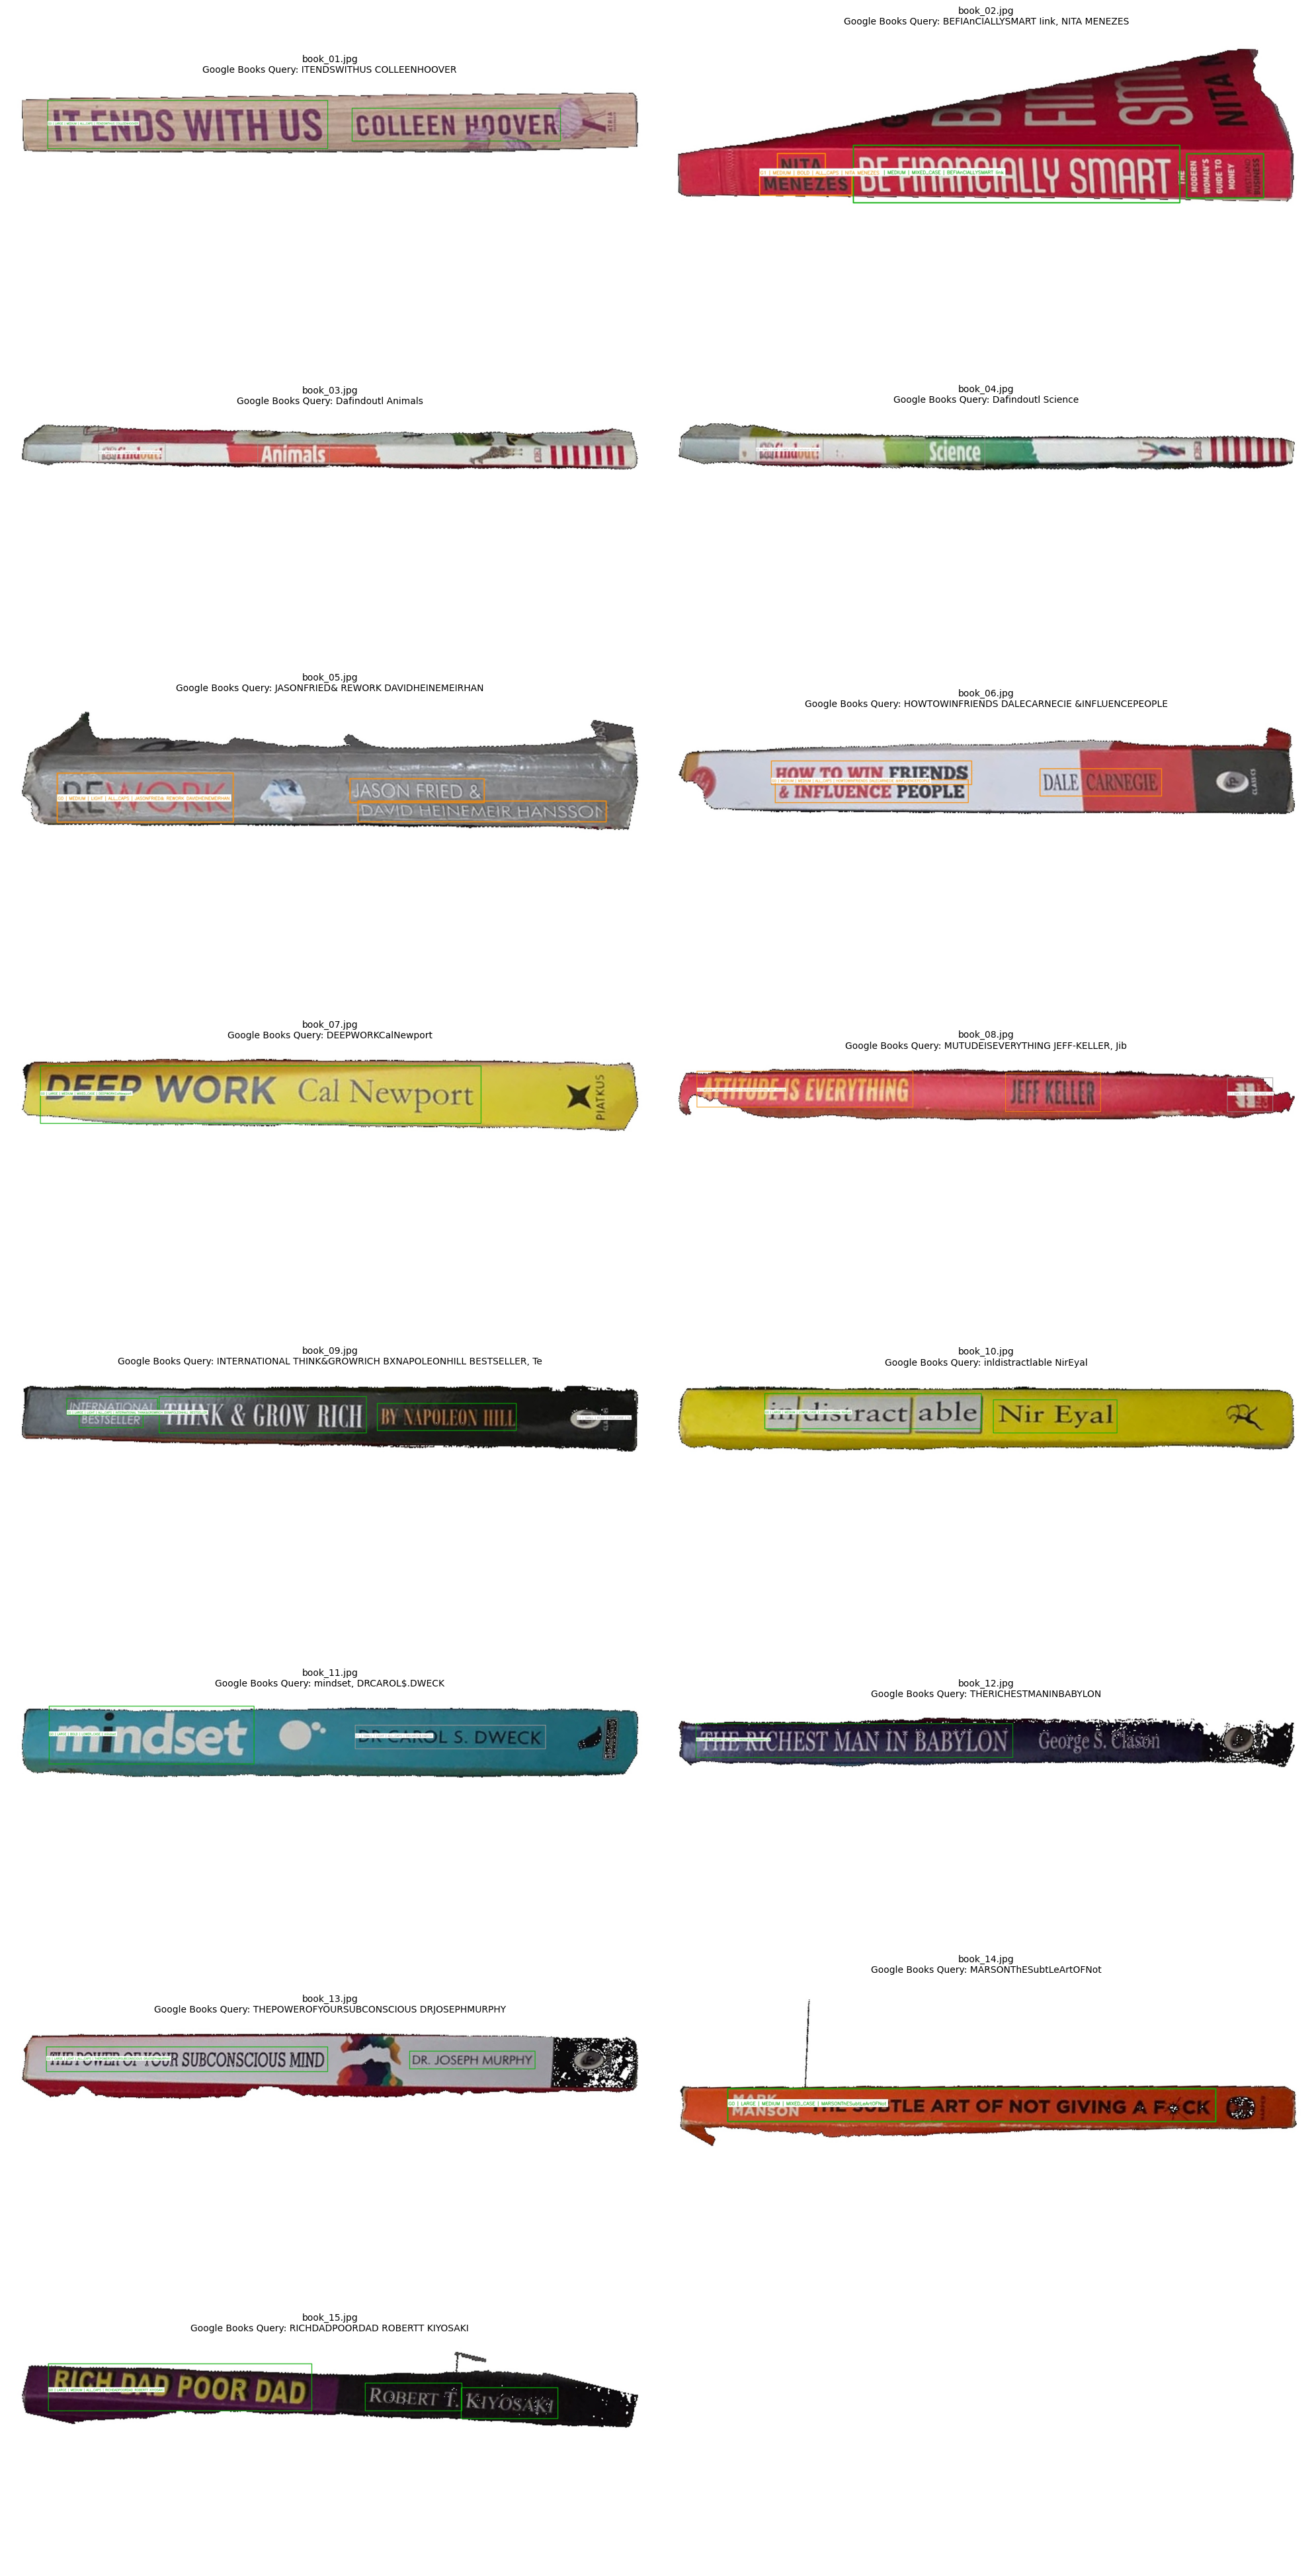

In [ ]:
# ============================================================
# PHASE 15 / STEP 23
# Display all annotated spines
# ============================================================

n = len(results)

if n:
    cols = 2
    row_count = math.ceil(n / cols)

    _, axes = plt.subplots(
        row_count,
        cols,
        figsize=(20, row_count * 5)
    )

    axes = np.asarray(axes).reshape(-1)

    for i, result in enumerate(results):
        ax = axes[i]

        path = (
            ANNOTATED_DIR
            / f"{Path(result['file']).stem}_typography.jpg"
        )

        image = cv2.imread(str(path))

        if image is not None:
            ax.imshow(
                cv2.cvtColor(
                    image,
                    cv2.COLOR_BGR2RGB
                )
            )

        ax.set_title(
            f"{result['file']}\n"
            f"Google Books Query: "
            f"{result['google_books_query']}",
            fontsize=10
        )
        ax.axis("off")

    for ax in axes[n:]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()


# PHASE 16 — Google Books API Preparation

## STEP 24 — Build API URLs without sending requests

The notebook does not automatically query the API. This avoids exhausting quota during repeated experiments.


In [ ]:
# ============================================================
# PHASE 16 / STEP 24
# Google Books API URL preparation
# ============================================================

from urllib.parse import quote_plus

GOOGLE_BOOKS_ENDPOINT = (
    "https://www.googleapis.com/books/v1/volumes"
)

def google_books_url(query,max_results=10):
    encoded=quote_plus(query.strip())
    return (
        f"{GOOGLE_BOOKS_ENDPOINT}"
        f"?q={encoded}"
        f"&maxResults={int(max_results)}"
    )

api_rows=[]

for result in results:
    query=result["google_books_query"]
    api_rows.append({
        "Book":result["file"],
        "Google Books Query":query,
        "Google Books URL":(
            google_books_url(query)
            if query else ""
        )
    })

api_df=pd.DataFrame(api_rows)
display(api_df)

api_df.to_csv(
    OUTPUT_DIR / "google_books_api_urls.csv",
    index=False
)


,Book,Google Books Query,Google Books URL
0,book_01.jpg,ITENDSWITHUS COLLEENHOOVER,https://www.googleapis.com/books/v1/volumes?q=...
1,book_02.jpg,"BEFIAnCIALLYSMART Iink, NITA MENEZES",https://www.googleapis.com/books/v1/volumes?q=...
2,book_03.jpg,Dafindoutl Animals,https://www.googleapis.com/books/v1/volumes?q=...
3,book_04.jpg,Dafindoutl Science,https://www.googleapis.com/books/v1/volumes?q=...
4,book_05.jpg,JASONFRIED& REWORK DAVIDHEINEMEIRHAN,https://www.googleapis.com/books/v1/volumes?q=...
5,book_06.jpg,HOWTOWINFRIENDS DALECARNECIE &INFLUENCEPEOPLE,https://www.googleapis.com/books/v1/volumes?q=...
6,book_07.jpg,DEEPWORKCalNewport,https://www.googleapis.com/books/v1/volumes?q=...
7,book_08.jpg,"MUTUDEISEVERYTHING JEFF-KELLER, Jib",https://www.googleapis.com/books/v1/volumes?q=...
8,book_09.jpg,INTERNATIONAL THINK&GROWRICH BXNAPOLEONHILL BE...,https://www.googleapis.com/books/v1/volumes?q=...
9,book_10.jpg,inldistractlable NirEyal,https://www.googleapis.com/books/v1/volumes?q=...


# PHASE 17 — Output Inventory

## STEP 25 — Generated files

```text
/content/BookSpine_OCR_Final_Output/
├── book_spine_google_books_queries.csv
├── typography_groups.csv
├── text_region_diagnostics.csv
├── google_books_api_urls.csv
├── normalized_spines/
└── annotated/
```

### Main production field

`Google Books Query`

Example:

```text
INTERNATIONAL, THINK & GROW RICH, NAPOLEON HILL
```


In [ ]:
# ============================================================
# PHASE 17 / STEP 25
# Final inventory
# ============================================================

print("================================================")
print("BOOK SPINE OCR — TYPOGRAPHY GROUPING COMPLETE")
print("================================================")
print("Query CSV      :", OUTPUT_DIR / "book_spine_google_books_queries.csv")
print("Typography CSV :", OUTPUT_DIR / "typography_groups.csv")
print("Region CSV     :", OUTPUT_DIR / "text_region_diagnostics.csv")
print("API URL CSV    :", OUTPUT_DIR / "google_books_api_urls.csv")
print("Annotated      :", ANNOTATED_DIR)
print("Normalized     :", NORMALIZED_DIR)
print("================================================")


BOOK SPINE OCR — TYPOGRAPHY GROUPING COMPLETE
Query CSV      : /content/BookSpine_OCR_Final_Output/book_spine_google_books_queries.csv
Typography CSV : /content/BookSpine_OCR_Final_Output/typography_groups.csv
Region CSV     : /content/BookSpine_OCR_Final_Output/text_region_diagnostics.csv
API URL CSV    : /content/BookSpine_OCR_Final_Output/google_books_api_urls.csv
Annotated      : /content/BookSpine_OCR_Final_Output/annotated
Normalized     : /content/BookSpine_OCR_Final_Output/normalized_spines
Text crops     : /content/BookSpine_OCR_Final_Output/text_crops
